**GitHub Link (contains .ipynb):**  https://github.com/avinashsriram1/ADSP-31011-Statistical-Models-for-Data-Science/tree/main/Assignment%203

# Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import OLSInfluence
from statsmodels.stats.anova import anova_lm
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, lasso_path
from sklearn.preprocessing import StandardScaler
from ISLP import load_data                       
from ISLP.models import ModelSpec as MS, summarize

plt.rcParams['figure.figsize'] = (6, 4)
pd.set_option('display.precision', 3)

Boston = load_data('Boston')
predictors = [c for c in Boston.columns if c != 'medv']   # the 12 candidate predictors

def fit_ols(terms, data=Boston, response='medv'):
    """Fit OLS of `response` on `terms` (a list of column names and/or interaction tuples)."""
    X = MS(terms).fit_transform(data)
    return sm.OLS(data[response], X).fit()

# Problem 1

In [2]:
# Part 1

display(Boston.head())

n_rows, n_cols = Boston.shape
print(f"Rows: {n_rows}")
print(f"Columns: {n_cols}")

print("\nData type of each column:")
print(Boston.dtypes)

print("\nMissing values per column:")
print(Boston.isna().sum())
print(f"\nTotal missing values: {Boston.isna().sum().sum()}")

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,0.006,18.0,2.31,0,0.538,6.575,65.2,4.090,1,296,15.3,4.98,24.0
1,0.027,0.0,7.07,0,0.469,6.421,78.9,4.967,2,242,17.8,9.14,21.6
2,0.027,0.0,7.07,0,0.469,7.185,61.1,4.967,2,242,17.8,4.03,34.7
3,0.032,0.0,2.18,0,0.458,6.998,45.8,6.062,3,222,18.7,2.94,33.4
4,0.069,0.0,2.18,0,0.458,7.147,54.2,6.062,3,222,18.7,5.33,36.2


Rows: 506
Columns: 13

Data type of each column:
crim       float64
zn         float64
indus      float64
chas         int64
nox        float64
rm         float64
age        float64
dis        float64
rad          int64
tax          int64
ptratio    float64
lstat      float64
medv       float64
dtype: object

Missing values per column:
crim       0
zn         0
indus      0
chas       0
nox        0
rm         0
age        0
dis        0
rad        0
tax        0
ptratio    0
lstat      0
medv       0
dtype: int64

Total missing values: 0


Part 2

Since each row is a census tract, a regression coefficient describes how neighborhood-level averages relate to each other, so interpreting it as information about individuals or households can be very misleading. Each coefficient is the expected change in a tract's median home value for a one-unit increase in that variable, holding the other variables constant. For example, if the lstat coefficient is negative, tracts with a higher percentage of lower-status residents tend to have lower median home values, but this does not imply that any one household's status changes the value of its own home. In other words, the data cannot tell us how a single house's price depends on these attributes. They only show relationships at the neighborhood level.

# Problem 2

In [8]:
# Part 1

summary = Boston.describe().T
summary['mean - median'] = summary['mean'] - summary['50%']
summary['(mean - median) / std'] = summary['mean - median'] / summary['std']
display(summary[['mean', '50%', 'std', 'min', 'max',
                 'mean - median', '(mean - median) / std']])

print("""Observations:
- zn, crim, tax, and rad have the largest positive gaps between mean and median (zn: 11.4 vs 0, crim: 3.6 vs 0.26, tax: 408 vs 330, rad: 9.5 vs 5). A mean above the median means a small number of very large values are pulling the mean upward, so these distributions are right-skewed. zn and crim are the most extreme: their medians sit at or near the minimum while their means are far higher.
- age is the only variable with a large negative gap (mean 68.6 vs median 77.5). A mean below the median means a few very small values are pulling the mean downward, so age is left-skewed (most tracts have mostly old housing).
- nox, rm, indus, and ptratio have means close to their medians, so they look roughly symmetric.
- chas is binary, so its mean (0.069) is just the share of tracts on the river and is not meaningful as a measure of skew.""")

,mean,50%,std,min,max,mean - median,(mean - median) / std
crim,3.614,0.257,8.602,0.006,88.976,3.357,0.390
zn,11.364,0.000,23.322,0.000,100.000,11.364,0.487
indus,11.137,9.690,6.860,0.460,27.740,1.447,0.211
chas,0.069,0.000,0.254,0.000,1.000,0.069,0.272
nox,0.555,0.538,0.116,0.385,0.871,0.017,0.144
rm,6.285,6.208,0.703,3.561,8.780,0.076,0.108
age,68.575,77.500,28.149,2.900,100.000,-8.925,-0.317
dis,3.795,3.207,2.106,1.130,12.127,0.588,0.279
rad,9.549,5.000,8.707,1.000,24.000,4.549,0.522
tax,408.237,330.000,168.537,187.000,711.000,78.237,0.464


Observations:
- zn, crim, tax, and rad have the largest positive gaps between mean and median (zn: 11.4 vs 0, crim: 3.6 vs 0.26, tax: 408 vs 330, rad: 9.5 vs 5). A mean above the median means a small number of very large values are pulling the mean upward, so these distributions are right-skewed. zn and crim are the most extreme: their medians sit at or near the minimum while their means are far higher.
- age is the only variable with a large negative gap (mean 68.6 vs median 77.5). A mean below the median means a few very small values are pulling the mean downward, so age is left-skewed (most tracts have mostly old housing).
- nox, rm, indus, and ptratio have means close to their medians, so they look roughly symmetric.
- chas is binary, so its mean (0.069) is just the share of tracts on the river and is not meaningful as a measure of skew.


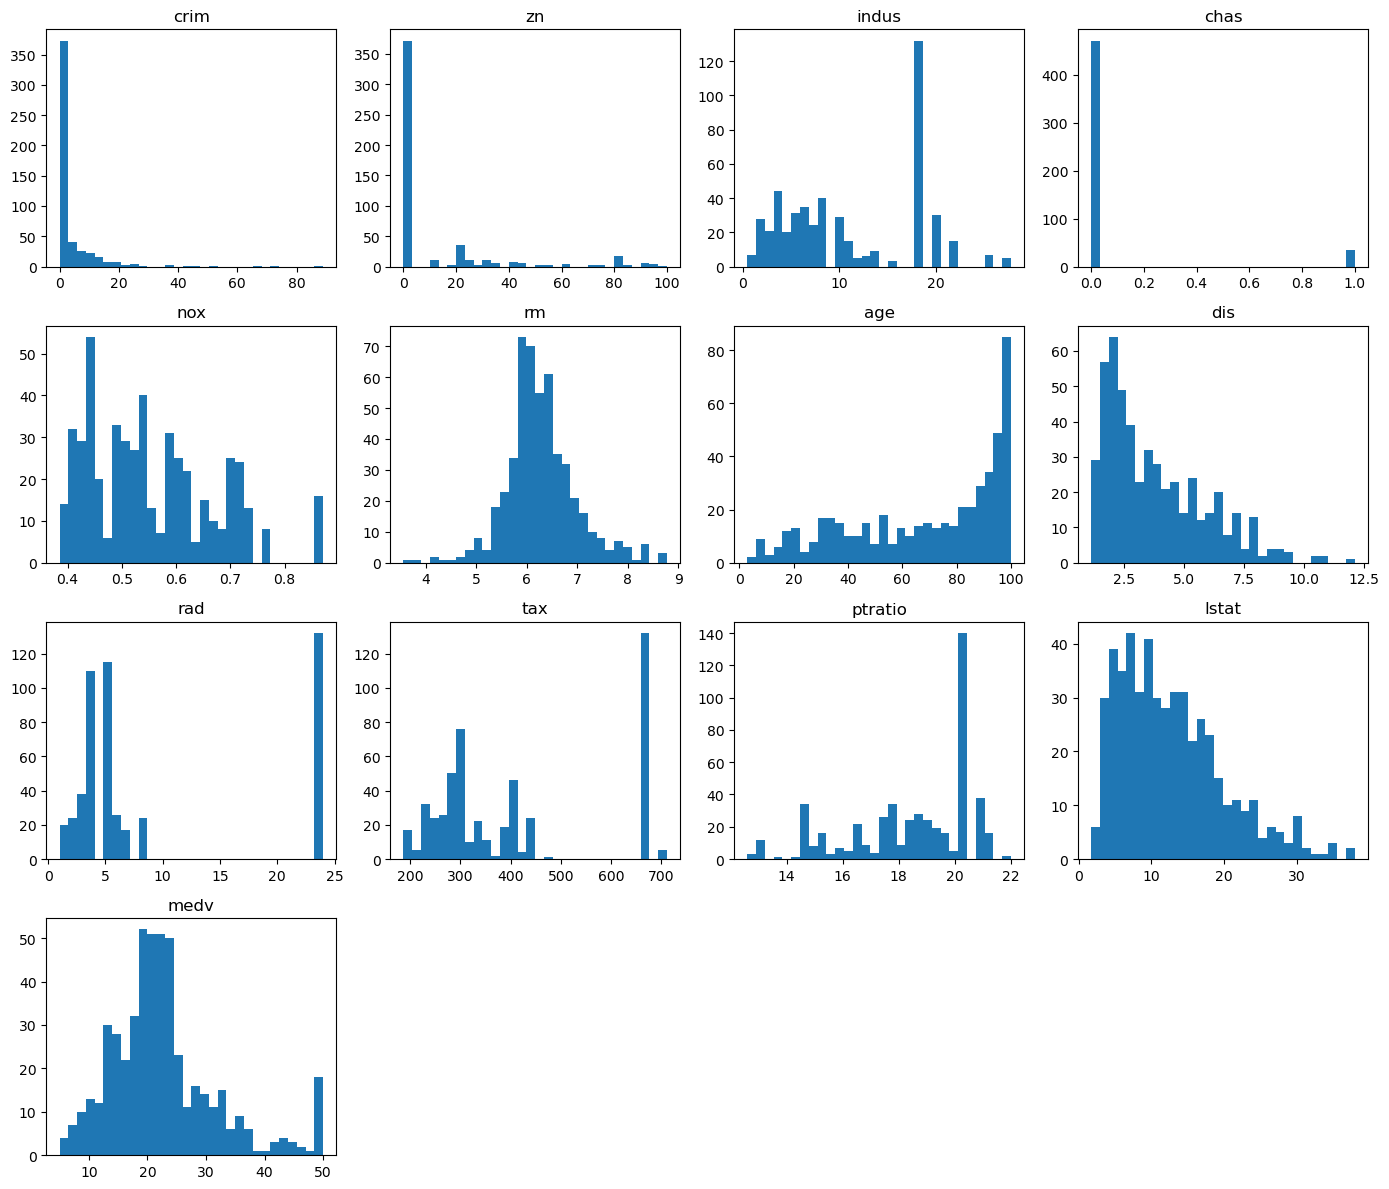

Skewness: In part 1, I expected zn and tax to have the most right skewed looking distribution and age to have a left skewed distribution. However, it seems a lot of the variables are more skewed than my intial analyis. crim, zn, nox, dis, and lstat all are right skewed. age is left skewed. chas seems to be bimodal. tax's distribution is unique due to the large mode it has (thereby raising the mean signficantly)

Spikes: There is a major spike in crim, zn, indus, chas, rad, tax, and ptratio variables

Categorical: Chas is effectively categorial as it is binary


In [9]:
# Part 2

fig, axs = plt.subplots(4, 4, figsize=(14, 12))
axs = axs.ravel()

for ax, col in zip(axs, Boston.columns):
    ax.hist(Boston[col], bins=30)
    ax.set_title(col)

for ax in axs[len(Boston.columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

print("Skewness: In part 1, I expected zn and tax to have the most right skewed looking distribution and age to have a left skewed distribution. However, it seems a lot of the variables are more skewed than my intial analyis. crim, zn, nox, dis, and lstat all are right skewed. age is left skewed. chas seems to be bimodal. tax's distribution is unique due to the large mode it has (thereby raising the mean signficantly)")
print("\nSpikes: There is a major spike in crim, zn, indus, chas, rad, tax, and ptratio variables")
print("\nCategorical: Chas is effectively categorial as it is binary")

Max medv: 50.0
Tracts with medv == 50.0: 16 (3.2% of 506)

Skewness of medv:      1.108
Skewness of log(medv): -0.330
Mean vs median of medv: 22.53 vs 21.20


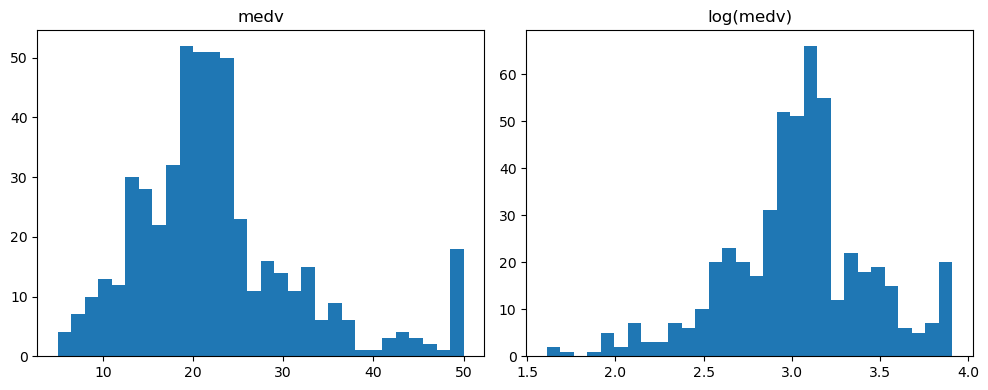

16 of the 506 values in the dataset have the maximum medv value (50.0). This could cuase trouble for a linear model because the median house value (medv) can be higher than 50.0 but the data essentially caps it off at 50. Since the linear model does not know that this is an intentional cap from the data curation itself, it will treat the values as true values and would underpredict the high median value tracts.
The data is slightly right skewed so I applied a log transformation to see if it would help correct the effects of the tail. After applying the changes, the distribution looks more bell-shaped so it could help here


In [12]:
# Part 3

max_medv = Boston['medv'].max()
n_capped = (Boston['medv'] == max_medv).sum()
print(f"Max medv: {max_medv}")
print(f"Tracts with medv == {max_medv}: {n_capped} ({n_capped / len(Boston):.1%} of {len(Boston)})")

log_medv = np.log(Boston['medv'])
print(f"\nSkewness of medv:      {Boston['medv'].skew():.3f}")
print(f"Skewness of log(medv): {log_medv.skew():.3f}")
print(f"Mean vs median of medv: {Boston['medv'].mean():.2f} vs {Boston['medv'].median():.2f}")

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].hist(Boston['medv'], bins=30)
axs[0].set_title('medv')
axs[1].hist(log_medv, bins=30)
axs[1].set_title('log(medv)')
plt.tight_layout()
plt.show()

print("16 of the 506 values in the dataset have the maximum medv value (50.0). This could cuase trouble for a linear model because the median house value (medv) can be higher than 50.0 but the data essentially caps it off at 50. Since the linear model does not know that this is an intentional cap from the data curation itself, it will treat the values as true values and would underpredict the high median value tracts.\nThe data is slightly right skewed so I applied a log transformation to see if it would help correct the effects of the tail. After applying the changes, the distribution looks more bell-shaped so it could help here")

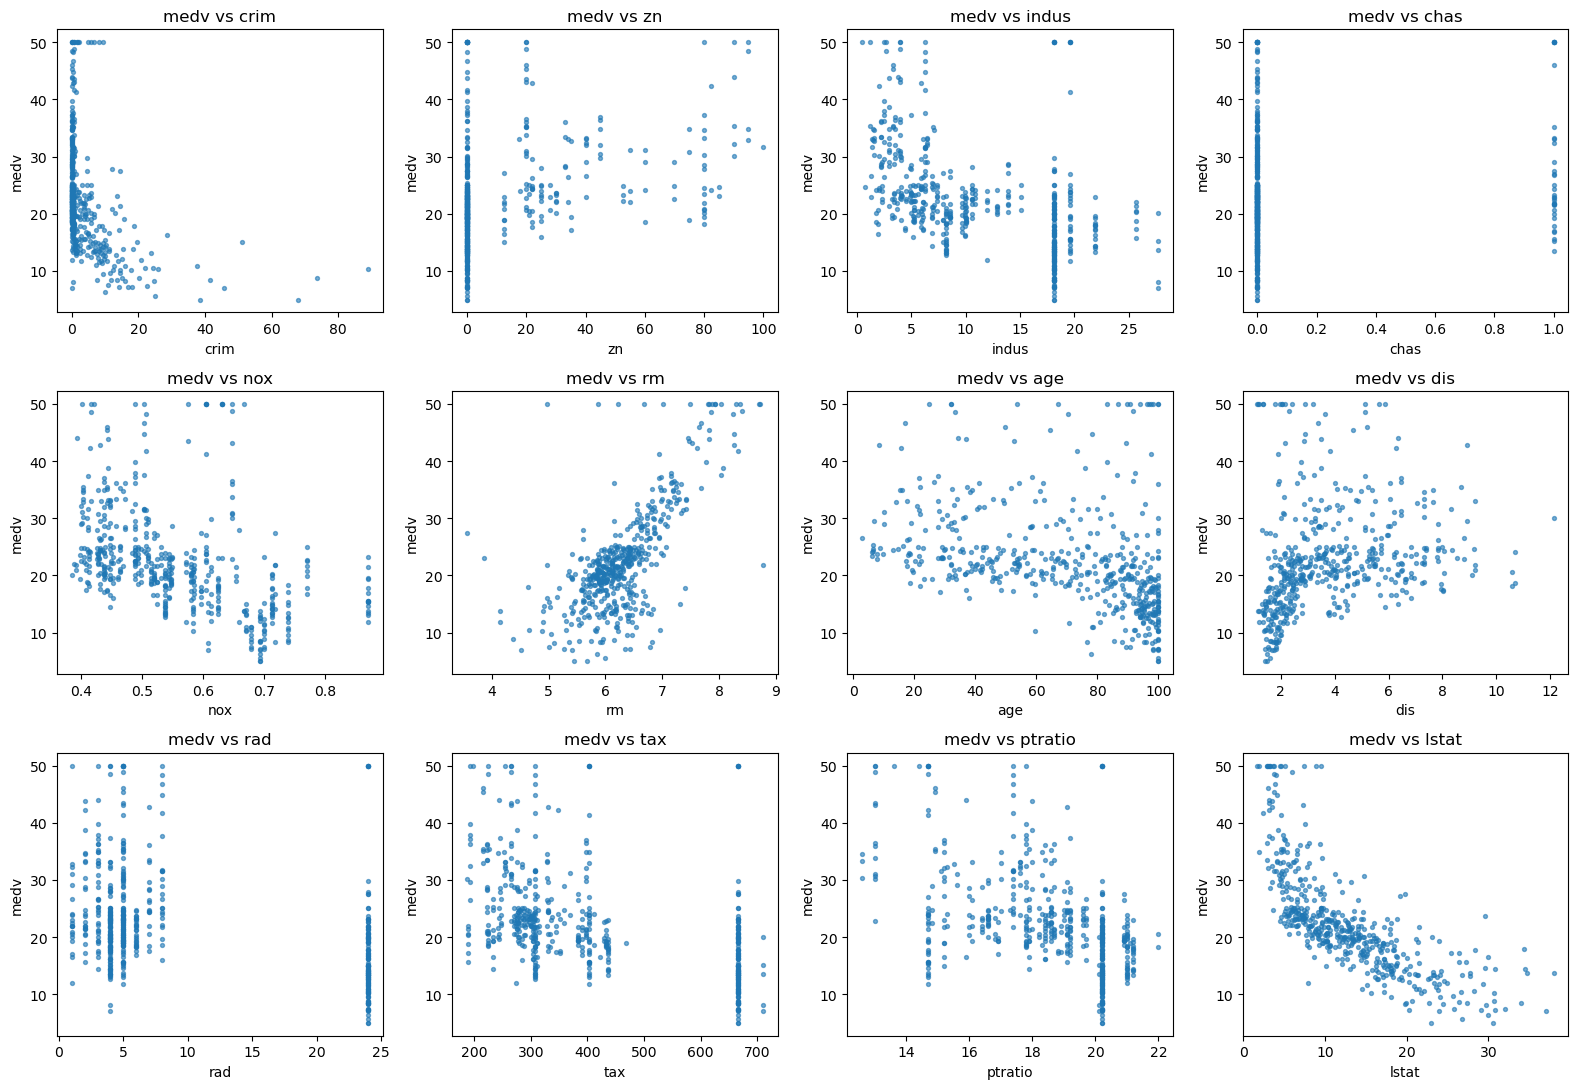

roughly linear:
- rm: Strong positive trend, since more rooms goes with a higher medv, with a fairly tight band along a straight line.
- nox: Moderate negative trend, with medv falling as pollution rises, though it is noisy and flattens at the highest values.
- ptratio: Mild negative trend, with a lot of scatter at each ratio.
- tax: Mild negative trend, though it is driven partly by a separate cluster of tracts at about 666, which sit mostly below 30.

looks curved:
- lstat: Clear convex curve, falling steeply at low lstat and flattening out above about 20%, so a straight line fits poorly.
- crim: Strongly L-shaped, with medv dropping quickly at low crime rates and nearly flat beyond about 20, because most of the data is bunched near 0.
- dis: medv rises sharply at short distances and then levels off (concave).
- indus: Declines steeply up to about 10 and then flattens, though the vertical stripe near 18 makes it hard to read.

looks weak:
- chas: Two vertical strips with heavily over

In [ ]:
# Part 4

fig, axs = plt.subplots(3, 4, figsize=(16, 11))
axs = axs.ravel()

for ax, col in zip(axs, predictors):
    ax.scatter(Boston[col], Boston['medv'], s=8, alpha=0.6)
    ax.set_xlabel(col)
    ax.set_ylabel('medv')
    ax.set_title(f'medv vs {col}')

plt.tight_layout()
plt.show()

print("""roughly linear:
- rm: Strong positive trend, since more rooms goes with a higher medv, with a fairly tight band along a straight line.
- nox: Moderate negative trend, with medv falling as pollution rises, though it is noisy and flattens at the highest values.
- ptratio: Mild negative trend, but has a some of scatter at each ratio.

looks curved:
- lstat: Has a curve, so a straight line fits poorly.
- crim: L-shaped, with medv dropping quickly at low crime rates and nearly flat beyond about 20, because most of the data is bunched near 0.
- dis: Has a concave curve shape as dis increases.
- indus: Declines steeply up to about 10 and then flattens, though the vertical stripe near 18 makes it hard to read.

looks weak:
- chas: Two vertical strips with heavily overlapping ranges.
- zn: Most tracts sit at 0 with the full range of medv.
- age: The oldest tracts (near 100) show a large spread on the medv.
- tax: Mild negative trend, but has a cluster of values would be difficult to model.
- rad: Discrete stripes with no clear trend, except the cluster at 24, which tends to be lower.""")

In [ ]:
# Part 5

In [ ]:
# Part 6

# Problem 3

# Problem 4

# Problem 5

# Problem 6

**Generative AI Use:**  